# 07. Cascade Spread Prediction & Virality Regression

- **Role/Owner:** Member 3 (Analytics, Graph & Visualization Lead)
- **Core Responsibility:** Train a Ridge Regression model that predicts how many **unique users** a rumour cascade will reach, from the author's followers and verified badge and from the **engagement velocity** of the first 30 minutes (FR2), and turn the prediction into a Low / Moderate / High spread risk.
- **Key Interface/Contract:** Consumes `backend/data/processed/cascade_features.csv` (splits) and `backend/data/processed/pheme_interactions.csv.gz` (one row per tweet, built by `backend/scripts/extract_pheme_interactions.py`); outputs `backend/models/spread_regressor.joblib` (read by `app/services/cascade.py`) and `backend/reports/spread_metrics.json`.

**Where the user and time data come from.** The graph file used in notebooks 01 and 02 (`pheme_political/pheme_cascades.gpickle`, from Hugging Face) has no user ids and no timestamps. The raw PHEME veracity release (figshare 6392078, CC BY 4.0) has both for every tweet. `extract_pheme_interactions.py` keeps only what this notebook and notebook 06 need, replaces the real user ids with keys such as `u123`, and drops the tweet text, so the table can live in the public repo.

**What this notebook does**

1. Load the 6,425 PHEME cascades with the same `split` column as the text models, so every model sees the same partition.
2. Build the target (unique users in the finished cascade) and the velocity features (replies in the first 5, 15, 30 and 60 minutes).
3. Check which columns are allowed. Columns measured from the finished cascade leak the answer and stay out.
4. Compare three models: a "predict the average" baseline, an **author-only** Ridge (followers and verified, used when velocity is not known yet) and the **main** Ridge (author + replies in the first 30 minutes). Tune `alpha` on validation, report the test set once.
5. Check the cascades that were still growing after 30 minutes, and events the model has never seen.
6. Turn predictions into Low / Moderate / High spread risk and save both models.

## 1. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SEED = 42
WINDOW = 30                         # engagement velocity = replies in the first 30 minutes (team decision)
WINDOWS = [5, 15, 30, 60]           # compared in Section 6
ALPHAS = np.logspace(-2, 4, 13)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").exists())
DATA = ROOT / "backend" / "data" / "processed"
MODELS = ROOT / "backend" / "models"
REPORTS = ROOT / "backend" / "reports"
MODELS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: /Users/phaman/Documents/COS30048 - Inno/inno


## 2. Load the cascades, the tweets and the splits

`cascade_features.csv` has one row per cascade and the `split` column: `train`, `val`, `test`, `excluded_label` and `excluded_dup`.

- `train / val / test` are the cascades whose source tweet is in the text-model splits. We use these.
- `excluded_label` are cascades dropped by the label rules (unverified rumours and two almost-all-false events). Spread prediction does not need the true/false label, so we test adding them as **Experiment B**, but keep them out of the main model so the comparison with the other notebooks stays fair.
- `excluded_dup` are cascades whose source text was a duplicate. We never use them, because a duplicate could appear in both train and test.

`pheme_interactions.csv.gz` has one row per tweet: thread, pseudonymous user key, the user it replies to, minutes after the source tweet, followers and verified flag.

In [2]:
df = pd.read_csv(DATA / "cascade_features.csv", dtype={"cascade_id": str})
tweets = pd.read_csv(DATA / "pheme_interactions.csv.gz", dtype={"thread_id": str})
assert len(df) == 6425, f"expected 6,425 cascades, found {len(df):,}"
assert tweets["thread_id"].nunique() == 6425 and set(tweets["thread_id"]) == set(df["cascade_id"])
print(f"{len(tweets):,} tweets from {tweets['user_key'].nunique():,} users")
print(df["split"].value_counts().to_string())

104,582 tweets from 50,593 users
split
train             3757
excluded_label     937
test               805
val                805
excluded_dup       121


## 3. Target and velocity features

- **Target: `unique_users`**, the number of different accounts that took part in the cascade (the author plus everyone who replied). FR2 asks for "expected audience reach (unique user count)". One user can reply several times, so this is smaller than the number of tweets.
- **Velocity: `replies_<W>m`**, the number of replies posted in the first W minutes after the source tweet. This is the "engagement velocity" in FR2. It is known W minutes after posting, long before the cascade has finished.
- **Author**: followers and verified flag of the source tweet's author, taken from the source tweet itself (the follower count at posting time).
- `last_reply_min` is when the last reply arrived. It is used only to find cascades that were still growing after the window, never as a feature.

In [3]:
source = tweets[tweets["is_source"] == 1].set_index("thread_id")
replies = tweets[tweets["is_source"] == 0]
by_thread = tweets.groupby("thread_id")

per = pd.DataFrame({
    "unique_users": by_thread["user_key"].nunique(),
    "last_reply_min": by_thread["minutes_after_source"].max(),
    "author_followers": source["user_followers"],
    "author_verified": source["user_verified"],
})
for w in WINDOWS:
    per[f"replies_{w}m"] = (replies[replies["minutes_after_source"] <= w]
                            .groupby("thread_id").size().reindex(per.index, fill_value=0))

df = df.merge(per, left_on="cascade_id", right_index=True, how="left", validate="one_to_one")
assert df[per.columns].notna().all().all()

follow_match = (df["author_followers"] == df["root_user_followers"]).mean()
print(f"author followers equal to the graph file's value in {follow_match:.1%} of cascades "
      "(the rest differ because the graph file stored another snapshot of the account)")
print(df[["unique_users", "cascade_size", f"replies_{WINDOW}m", "last_reply_min"]]
      .describe(percentiles=[.5, .9, .99]).round(1).to_string())

author followers equal to the graph file's value in 88.0% of cascades (the rest differ because the graph file stored another snapshot of the account)
       unique_users  cascade_size  replies_30m  last_reply_min
count        6425.0        6425.0       6425.0          6425.0
mean           10.8          16.5          7.4           892.3
std             7.7          19.8          8.2          2342.3
min             1.0           1.0          0.0             0.0
50%            10.0          12.0          5.0           157.0
90%            20.0          32.0         18.0          2112.5
99%            33.0          99.8         33.0         11552.2
max           125.0         346.0        145.0         43725.4


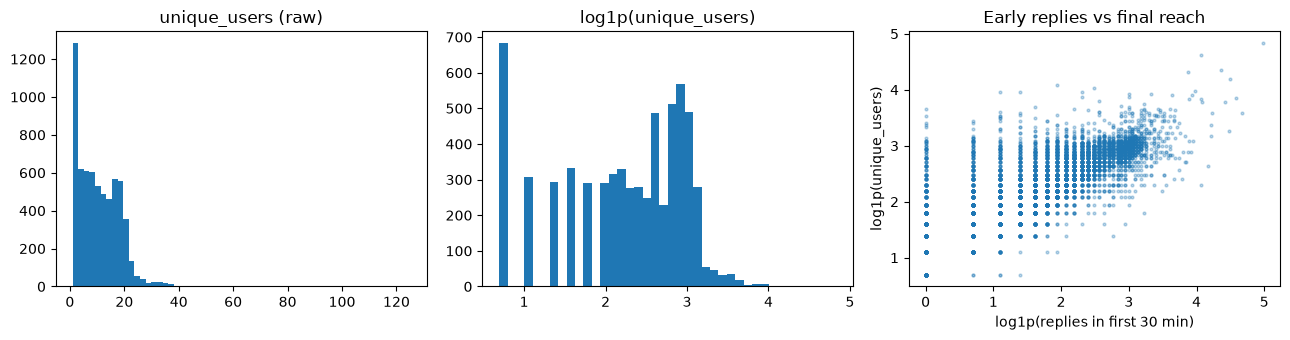

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(df["unique_users"], bins=60)
ax[0].set_title("unique_users (raw)")
ax[1].hist(np.log1p(df["unique_users"]), bins=40)
ax[1].set_title("log1p(unique_users)")
ax[2].scatter(np.log1p(df[f"replies_{WINDOW}m"]), np.log1p(df["unique_users"]), s=4, alpha=0.3)
ax[2].set_xlabel(f"log1p(replies in first {WINDOW} min)")
ax[2].set_ylabel("log1p(unique_users)")
ax[2].set_title("Early replies vs final reach")
plt.tight_layout()
plt.show()

The reach is skewed (most cascades are small, a few are large), so the models are trained on `log1p(unique_users)` and converted back with `expm1` for real user counts.

## 4. Which columns are allowed

| Column | Use | Reason |
|---|---|---|
| `author_followers` | feature (log) | known before the cascade starts |
| `author_verified` | feature | known before the cascade starts |
| `replies_30m` | feature (log), main model only | known 30 minutes after posting |
| `max_depth`, `reply_count`, `n_unique_verified`, `cascade_size` | **not used** | measured from the finished cascade, so they leak the target |
| `label`, `veracity` | not used | not known for a new claim (the dashboard predicts veracity with a separate model) |
| `event` | not used for training | a new claim has no event label; used only to test on unseen events |

The table below shows the Spearman correlation of every candidate with the target.

In [5]:
USED = ["train", "val", "test"]
pool = df[df["split"].isin(USED)]
candidates = ["author_followers", "author_verified"] + [f"replies_{w}m" for w in WINDOWS] + \
             ["max_depth", "reply_count", "n_unique_verified", "cascade_size"]
corr = (pool[["unique_users"] + candidates].corr(method="spearman")["unique_users"]
        .drop("unique_users").round(3).rename("spearman vs unique_users"))
corr.to_frame()

,spearman vs unique_users
author_followers,0.243
author_verified,0.173
replies_5m,0.618
replies_15m,0.733
replies_30m,0.784
replies_60m,0.820
max_depth,0.650
reply_count,0.928
n_unique_verified,0.252
cascade_size,0.900


## 5. Models, metrics and baseline

Each model is a scikit-learn pipeline: log-transform and standardise the counts, pass the verified flag through, then Ridge regression. The transforms live inside the pipeline, so the API can send raw numbers.

Metrics (validation or test only, never training data):

- **R2 (log scale)**: share of variance explained. 0 means "no better than predicting the average".
- **MAE (users)**: average error in real user counts.
- **Spearman**: does the model rank big cascades above small ones? This matters for the risk levels.

`alpha` (the size of the Ridge penalty) is picked on the validation set from 13 values between 0.01 and 10,000.

train            3757 cascades | median unique users 10
val               805 cascades | median unique users 10
test              805 cascades | median unique users 10
excluded_label    937 cascades | median unique users 7
baseline always predicts 8.6 users
alpha author-only: 100.0 | alpha main: 0.01


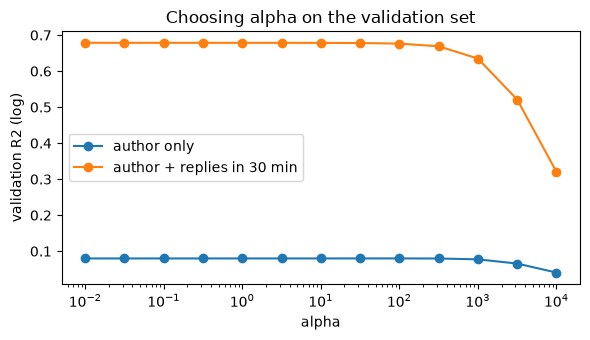

In [6]:
AUTHOR = ["author_followers", "author_verified"]
MAIN = AUTHOR + [f"replies_{WINDOW}m"]

train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()
extra = df[df["split"] == "excluded_label"].copy()     # only for Experiment B
for name, d in [("train", train), ("val", val), ("test", test), ("excluded_label", extra)]:
    print(f"{name:15s} {len(d):5d} cascades | median unique users {d['unique_users'].median():.0f}")


def make_pipeline(features, alpha):
    counts = [f for f in features if f != "author_verified"]
    steps = [("counts", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), counts)]
    if "author_verified" in features:
        steps.append(("verified", "passthrough", ["author_verified"]))
    return Pipeline([("prep", ColumnTransformer(steps)), ("ridge", Ridge(alpha=alpha))])


def target(d):
    return np.log1p(d["unique_users"].to_numpy())


def rank_corr(a, b):
    return float("nan") if np.ptp(b) < 1e-9 else float(spearmanr(a, b)[0])


def evaluate(model, d, features):
    y_log, p_log = target(d), model.predict(d[features])
    p_users = np.expm1(p_log)
    return {
        "r2_log": float(r2_score(y_log, p_log)),
        "mae_users": float(mean_absolute_error(d["unique_users"], p_users)),
        "rmse_users": float(np.sqrt(mean_squared_error(d["unique_users"], p_users))),
        "spearman": rank_corr(d["unique_users"], p_log),
    }


def tune(features, fit_rows, val_rows):
    """Pick alpha on val_rows, then return the model refitted on fit_rows with that alpha."""
    scores = [evaluate(make_pipeline(features, a).fit(fit_rows[features], target(fit_rows)), val_rows, features)["r2_log"]
              for a in ALPHAS]
    best = float(ALPHAS[int(np.argmax(scores))])
    return make_pipeline(features, best).fit(fit_rows[features], target(fit_rows)), best, scores


baseline = DummyRegressor(strategy="mean").fit(train[AUTHOR], target(train))
author_model, alpha_author, scores_author = tune(AUTHOR, train, val)
model, best_alpha, scores_main = tune(MAIN, train, val)
print("baseline always predicts", round(float(np.expm1(baseline.constant_[0][0])), 1), "users")
print("alpha author-only:", alpha_author, "| alpha main:", best_alpha)

plt.figure(figsize=(6, 3.5))
plt.semilogx(ALPHAS, scores_author, marker="o", label="author only")
plt.semilogx(ALPHAS, scores_main, marker="o", label=f"author + replies in {WINDOW} min")
plt.xlabel("alpha"); plt.ylabel("validation R2 (log)"); plt.legend()
plt.title("Choosing alpha on the validation set")
plt.tight_layout(); plt.show()

In [7]:
results = pd.DataFrame({
    "baseline val": evaluate(baseline, val, AUTHOR),
    "author-only val": evaluate(author_model, val, AUTHOR),
    "main val": evaluate(model, val, MAIN),
    "baseline test": evaluate(baseline, test, AUTHOR),
    "author-only test": evaluate(author_model, test, AUTHOR),
    "main test": evaluate(model, test, MAIN),
}).T.round(3)
results

,r2_log,mae_users,rmse_users,spearman
baseline val,-0.000,6.149,7.784,NaN
author-only val,0.080,5.866,7.505,0.262
main val,0.679,3.232,4.975,0.805
baseline test,-0.000,6.268,8.941,NaN
author-only test,0.056,6.075,8.820,0.197
main test,0.629,3.578,5.719,0.764


## 6. How early can we warn? The velocity window

A longer window always helps, because the model has seen more of the cascade. The table shows the trade-off on the validation set: how much accuracy each window buys, and how many cascades had already received their last reply by then (for those, the "prediction" is mostly a count). The team chose 30 minutes as the main window before looking at the test set.

In [8]:
rows = []
for w in WINDOWS:
    feats = AUTHOR + [f"replies_{w}m"]
    m_w, a_w, _ = tune(feats, train, val)
    rows.append({"window_min": w, "alpha": a_w, **evaluate(m_w, val, feats),
                 "val_already_finished": float((val["last_reply_min"] <= w).mean())})
window_table = pd.DataFrame(rows).round(3)
window_table

,window_min,alpha,r2_log,mae_users,rmse_users,spearman,val_already_finished
0,5,0.01,0.384,4.552,6.359,0.609,0.097
1,15,0.01,0.572,3.736,5.545,0.746,0.130
2,30,0.01,0.679,3.232,4.975,0.805,0.190
3,60,0.01,0.733,2.892,4.729,0.838,0.291


## 7. The honest case: cascades still growing after 30 minutes

For a cascade whose last reply came within the first 30 minutes, the feature already contains almost the whole answer. The useful forecasts are for cascades that keep growing. We score the test cascades with at least one reply after the window separately.

In [9]:
growing = test[test["last_reply_min"] > WINDOW]
print(f"test cascades still growing after {WINDOW} min: {len(growing)} of {len(test)} ({len(growing) / len(test):.0%})")
growing_results = pd.DataFrame({
    "baseline": evaluate(baseline, growing, AUTHOR),
    "author-only": evaluate(author_model, growing, AUTHOR),
    "main": evaluate(model, growing, MAIN),
}).T.round(3)
growing_results

test cascades still growing after 30 min: 651 of 805 (81%)


,r2_log,mae_users,rmse_users,spearman
baseline,-0.158,6.244,9.376,NaN
author-only,-0.187,6.135,9.311,0.112
main,0.390,3.854,6.164,0.684


## 8. Experiment B: add the `excluded_label` cascades to training

Spread prediction does not need to know whether a rumour is true, so the `excluded_label` cascades are valid data. We add them to training only (validation and test stay the same). If the result is about the same, the simpler setup stays as the main model.

In [10]:
train_b = pd.concat([train, extra])
model_b = make_pipeline(MAIN, best_alpha).fit(train_b[MAIN], target(train_b))
exp_b = pd.DataFrame({
    "A: train only (val)": evaluate(model, val, MAIN),
    "B: train + excluded_label (val)": evaluate(model_b, val, MAIN),
    "A: train only (test)": evaluate(model, test, MAIN),
    "B: train + excluded_label (test)": evaluate(model_b, test, MAIN),
}).T.round(3)
exp_b

,r2_log,mae_users,rmse_users,spearman
A: train only (val),0.679,3.232,4.975,0.805
B: train + excluded_label (val),0.677,3.212,5.051,0.806
A: train only (test),0.629,3.578,5.719,0.764
B: train + excluded_label (test),0.622,3.583,5.759,0.765


## 9. Events the model has never seen

The text models score much lower on events they never saw, because they partly learn the event. The same risk applies here: some events produce bigger cascades than others. We hold out one event at a time (events with at least 400 cascades). Inside each fold, `alpha` is tuned on the validation rows of the **other** events and the model is fitted on their training rows, so the held-out event never influences training or tuning.

In [11]:
big_events = pool["event"].value_counts()
big_events = big_events[big_events >= 400].index.tolist()

rows = []
for ev in big_events:
    rest, held = pool[pool["event"] != ev], pool[pool["event"] == ev]
    fit_rows, val_rows = rest[rest["split"] == "train"], rest[rest["split"] == "val"]
    m_main, _, _ = tune(MAIN, fit_rows, val_rows)
    m_auth, _, _ = tune(AUTHOR, fit_rows, val_rows)
    dummy = DummyRegressor(strategy="mean").fit(fit_rows[AUTHOR], target(fit_rows))
    r, a, d = evaluate(m_main, held, MAIN), evaluate(m_auth, held, AUTHOR), evaluate(dummy, held, AUTHOR)
    rows.append({"held-out event": ev.replace("-all-rnr-threads", ""), "cascades": len(held),
                 "main R2": r["r2_log"], "author-only R2": a["r2_log"], "baseline R2": d["r2_log"],
                 "main MAE": r["mae_users"], "baseline MAE": d["mae_users"], "main Spearman": r["spearman"]})
loeo = pd.DataFrame(rows).round(3)
print("mean R2 over unseen events: main", round(loeo["main R2"].mean(), 3),
      "| author-only", round(loeo["author-only R2"].mean(), 3), "| baseline", round(loeo["baseline R2"].mean(), 3))
loeo

mean R2 over unseen events: main 0.6 | author-only -0.116 | baseline -0.135


,held-out event,cascades,main R2,author-only R2,baseline R2,main MAE,baseline MAE,main Spearman
0,charliehebdo,1884,0.459,-0.040,-0.091,3.624,5.975,0.717
1,sydneysiege,1145,0.685,-0.132,-0.178,3.300,6.658,0.780
2,ferguson,854,0.499,0.007,-0.004,4.953,7.480,0.716
3,ottawashooting,810,0.669,0.083,-0.000,2.778,5.504,0.817
4,germanwings-crash,433,0.686,-0.498,-0.400,2.380,5.415,0.877


## 10. What the model learned

The coefficients are for standardised inputs, so they can be compared within a model. The plots show predicted against actual reach on the test set, and the residuals.

                       author-only    main
log followers               0.1916 -0.0242
log replies in 30 min          NaN  0.6196
verified                    0.0503 -0.0331
intercept main: 2.2756


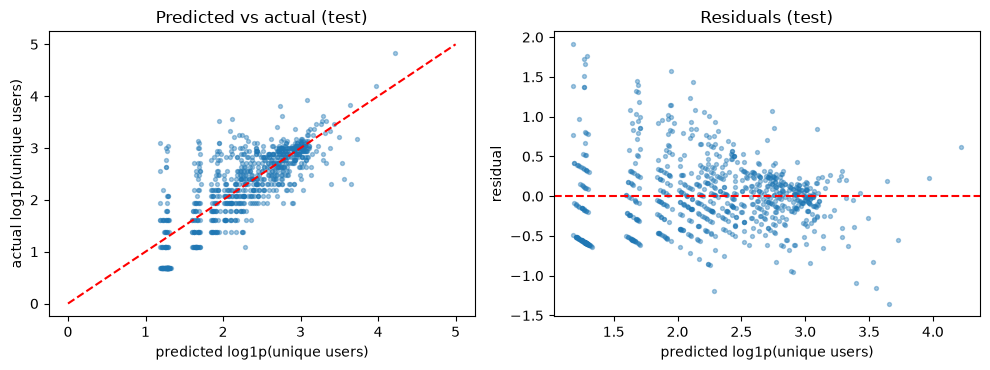

In [12]:
names = {"author_followers": "log followers", "author_verified": "verified", f"replies_{WINDOW}m": f"log replies in {WINDOW} min"}


def coefs_of(m, features):
    counts = [f for f in features if f != "author_verified"]
    order = counts + (["author_verified"] if "author_verified" in features else [])
    return pd.Series(m.named_steps["ridge"].coef_, index=[names[f] for f in order])


coefs = pd.DataFrame({"author-only": coefs_of(author_model, AUTHOR), "main": coefs_of(model, MAIN)}).round(4)
print(coefs.to_string())
print("intercept main:", round(float(model.named_steps["ridge"].intercept_), 4))

p_test = model.predict(test[MAIN])
y_test = target(test)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(p_test, y_test, s=8, alpha=0.4)
ax[0].plot([0, 5], [0, 5], color="red", linestyle="--")
ax[0].set_xlabel("predicted log1p(unique users)"); ax[0].set_ylabel("actual log1p(unique users)")
ax[0].set_title("Predicted vs actual (test)")
ax[1].scatter(p_test, y_test - p_test, s=8, alpha=0.4)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("predicted log1p(unique users)"); ax[1].set_ylabel("residual")
ax[1].set_title("Residuals (test)")
plt.tight_layout(); plt.show()

## 11. From a number to a spread-risk level

The dashboard shows Low, Moderate or High. PHEME cascades are small, so fixed thresholds such as 1,000 or 10,000 users do not fit. We split the main model's **predicted** values on the training set into three equal groups and use those two cut points, then check on the test set that the groups really separate small cascades from big ones. The author-only fallback gets its own cut points the same way.

In [13]:
def cut_points(m, features):
    return tuple(float(x) for x in np.quantile(m.predict(train[features]), [1 / 3, 2 / 3]))


def risk_level(p_log, cuts):
    low, high = cuts
    return np.where(p_log < low, "Low", np.where(p_log < high, "Moderate", "High"))


def risk_table(m, features, cuts, d):
    level = pd.Series(risk_level(m.predict(d[features]), cuts), index=d.index, name="risk")
    return (d.groupby(level)["unique_users"].agg(cascades="size", mean_users="mean", median_users="median")
            .reindex(["Low", "Moderate", "High"]).round(1))


cuts_main, cuts_author = cut_points(model, MAIN), cut_points(author_model, AUTHOR)
risk_main = risk_table(model, MAIN, cuts_main, test)
risk_author = risk_table(author_model, AUTHOR, cuts_author, test)
print(f"main cut points: {np.expm1(cuts_main[0]):.1f} and {np.expm1(cuts_main[1]):.1f} predicted users")
print(risk_main.to_string())
print()
print(f"author-only cut points: {np.expm1(cuts_author[0]):.1f} and {np.expm1(cuts_author[1]):.1f} predicted users")
print(risk_author.to_string())

main cut points: 6.6 and 12.6 predicted users
          cascades  mean_users  median_users
risk                                        
Low            266         5.3           4.0
Moderate       259        10.5           9.0
High           280        17.7          17.0

author-only cut points: 7.6 and 9.5 predicted users
          cascades  mean_users  median_users
risk                                        
Low            267         9.8           8.0
Moderate       249        11.6          10.0
High           289        12.3          12.0


## 12. Save the models and the report

The `.joblib` file is a dictionary with both pipelines. The backend uses the main model when the request includes the number of replies in the first 30 minutes, and the author-only model otherwise:

```python
art = joblib.load("backend/models/spread_regressor.joblib")
X = pd.DataFrame({"author_followers": [450000], "author_verified": [1], "replies_30m": [12]})
users = float(np.expm1(art["model"].predict(X))[0])
```

In [14]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer):
        return int(o)
    return o


versions = {"sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}

artifact = {
    "model": model,
    "features": MAIN,
    "model_author_only": author_model,
    "features_author_only": AUTHOR,
    "velocity_window_min": WINDOW,
    "target": "log1p(unique_users); predicted users = expm1(model.predict(X))",
    "alpha": {"main": best_alpha, "author_only": alpha_author},
    "risk_cut_points_log": {"main": {"low_below": cuts_main[0], "high_from": cuts_main[1]},
                            "author_only": {"low_below": cuts_author[0], "high_from": cuts_author[1]}},
    "risk_cut_points_users": {"main": {"low_below": float(np.expm1(cuts_main[0])), "high_from": float(np.expm1(cuts_main[1]))},
                              "author_only": {"low_below": float(np.expm1(cuts_author[0])), "high_from": float(np.expm1(cuts_author[1]))}},
    "trained_on": "split == 'train'",
    "versions": versions,
}
joblib.dump(artifact, MODELS / "spread_regressor.joblib")

report = {
    "data": {"cascades": len(df), "tweets": len(tweets), "train": len(train), "val": len(val), "test": len(test),
             "excluded_label": len(extra), "excluded_dup": int((df["split"] == "excluded_dup").sum())},
    "target": "log1p(unique_users)",
    "features": {"main": MAIN, "author_only": AUTHOR},
    "velocity_window_min": WINDOW,
    "alpha": artifact["alpha"],
    "leakage_check_spearman": corr.to_dict(),
    "results": results.to_dict(orient="index"),
    "window_scan_val": window_table.to_dict(orient="records"),
    "still_growing_test": {"cascades": len(growing), "results": growing_results.to_dict(orient="index")},
    "experiment_b": exp_b.to_dict(orient="index"),
    "leave_one_event_out": loeo.to_dict(orient="records"),
    "coefficients": coefs.to_dict(),
    "risk_table_test": {"main": risk_main.to_dict(orient="index"), "author_only": risk_author.to_dict(orient="index")},
    "risk_cut_points_users": artifact["risk_cut_points_users"],
    "versions": versions,
    "seed": SEED,
}
with open(REPORTS / "spread_metrics.json", "w", encoding="utf-8") as f:
    json.dump(clean(report), f, indent=2)
print("saved:", MODELS / "spread_regressor.joblib")
print("saved:", REPORTS / "spread_metrics.json")

saved: /Users/phaman/Documents/COS30048 - Inno/inno/backend/models/spread_regressor.joblib
saved: /Users/phaman/Documents/COS30048 - Inno/inno/backend/reports/spread_metrics.json


In [15]:
# Reload test: this is what the backend will do, with and without the velocity input
art = joblib.load(MODELS / "spread_regressor.joblib")
sample = pd.DataFrame({"author_followers": [450_000, 800, 25_000_000],
                       "author_verified": [1, 0, 1],
                       f"replies_{WINDOW}m": [12, 1, 3]})
cuts = art["risk_cut_points_log"]
p_main = art["model"].predict(sample[art["features"]])
p_auth = art["model_author_only"].predict(sample[art["features_author_only"]])
print(pd.DataFrame({
    "followers": sample["author_followers"], "verified": sample["author_verified"],
    f"replies_{WINDOW}m": sample[f"replies_{WINDOW}m"],
    "users (main)": np.expm1(p_main).round(1),
    "risk (main)": risk_level(p_main, (cuts["main"]["low_below"], cuts["main"]["high_from"])),
    "users (author only)": np.expm1(p_auth).round(1),
    "risk (author only)": risk_level(p_auth, (cuts["author_only"]["low_below"], cuts["author_only"]["high_from"])),
}).to_string(index=False))

 followers  verified  replies_30m  users (main) risk (main)  users (author only) risk (author only)
    450000         1           12          14.6        High                 10.1               High
       800         0            1           4.5         Low                  5.9                Low
  25000000         1            3           6.4         Low                 13.6               High


### Numbers quoted in the Discussion

Every number in the Discussion below is printed here or in an earlier cell, so it cannot go stale on a re-run.

In [16]:
by_event = pool.groupby("event")["unique_users"].median().rename(lambda e: e.replace("-all-rnr-threads", ""))
up_to_100 = ALPHAS <= 100
facts = {
    "test R2 main / author-only / baseline": results.loc[["main test", "author-only test", "baseline test"], "r2_log"].tolist(),
    "test MAE users main / author-only / baseline": results.loc[["main test", "author-only test", "baseline test"], "mae_users"].tolist(),
    "test Spearman main / author-only": results.loc[["main test", "author-only test"], "spearman"].tolist(),
    "growing after window: cascades": len(growing),
    "growing after window: R2 main / author-only / baseline": growing_results["r2_log"].loc[["main", "author-only", "baseline"]].tolist(),
    "growing after window: MAE main / baseline": growing_results["mae_users"].loc[["main", "baseline"]].tolist(),
    "main validation R2 for alpha 0.01 to 100 (min, max)": [round(float(np.min(np.array(scores_main)[up_to_100])), 3),
                                                            round(float(np.max(np.array(scores_main)[up_to_100])), 3)],
    "median unique users / median cascade_size (train+val+test)": [float(pool["unique_users"].median()), float(pool["cascade_size"].median())],
    "max unique users (train+val+test)": int(pool["unique_users"].max()),
    "median unique users by event": {k: float(v) for k, v in by_event.items()},
}
for k, v in facts.items():
    print(f"{k}: {v}")

test R2 main / author-only / baseline: [0.629, 0.056, -0.0]
test MAE users main / author-only / baseline: [3.578, 6.075, 6.268]
test Spearman main / author-only: [0.764, 0.197]
growing after window: cascades: 651
growing after window: R2 main / author-only / baseline: [0.39, -0.187, -0.158]
growing after window: MAE main / baseline: [3.854, 6.244]
main validation R2 for alpha 0.01 to 100 (min, max): [0.676, 0.679]
median unique users / median cascade_size (train+val+test): [10.0, 13.0]
max unique users (train+val+test): 125
median unique users by event: {'charliehebdo': 11.0, 'ferguson': 11.0, 'germanwings-crash': 5.0, 'gurlitt': 1.0, 'ottawashooting': 9.0, 'putinmissing': 2.0, 'sydneysiege': 13.0}


## 13. Discussion

**1. Engagement velocity is what makes the model work.** On the test set the main model (author + replies in the first 30 minutes) reaches R2 = 0.629 on the log scale, against 0.056 for the author-only model and 0.000 for the "predict the average" baseline. Its average error is 3.6 users, against 6.1 and 6.3, and its rank correlation is 0.764 against 0.197. The correlation table in Section 4 already pointed this way: replies in the first 30 minutes correlate 0.784 with the final number of users, the follower count only 0.243.

**2. The honest case.** 19% of the validation cascades had received their last reply within 30 minutes, and for them the feature is close to the answer. On the 651 test cascades (81%) that were still growing after 30 minutes, the main model still explains a good share of the differences (R2 0.390, average error 3.9 users against 6.2 for the baseline), while the author-only model is worse than the average (-0.187). So the forecast is useful for the cascades where a forecast matters.

**3. Earlier or more accurate.** Section 6 shows the trade-off. After 5 minutes the validation R2 is 0.384, after 15 minutes 0.572, after 30 minutes 0.679 and after 60 minutes 0.733, while the share of cascades already finished grows from 10% to 29%. The team chose 30 minutes as the main window because it keeps most of the accuracy while most cascades are still growing.

**4. Events the model has never seen.** The earlier author-only model did worse than the average on unseen events. With velocity, the mean R2 over the five big held-out events is 0.600, every event is positive (from 0.459 for Charlie Hebdo to 0.686 for Germanwings), and the average error is lower than the baseline in all five. The author-only model averages -0.116 and the baseline -0.135. Velocity carries over to new events because it measures how this particular cascade is taking off, while the size of a typical cascade depends strongly on the event (median 13 users in the Sydney siege, 11 in Charlie Hebdo and Ferguson, 5 in Germanwings and 1 in Gurlitt).

**5. Which feature matters.** In the main model the standardised coefficient of log replies in 30 minutes is +0.62, while log followers (-0.02) and verified (-0.03) are close to zero. Once the early replies are known, the author's reach adds nothing: a big account whose post gets few early replies is not going to spread far. In the author-only model, followers carry the signal (+0.19) and the badge is small (+0.05). The validation R2 of the main model barely changes with `alpha` (0.676 to 0.679 for alpha 0.01 to 100), because three features and 3,757 cascades do not need much regularisation; the smallest value tried was picked.

**6. Spread-risk levels.** The main model's cut points fall at 6.6 and 12.6 predicted users. On the test set the three levels separate clearly: median 4 users for Low, 9 for Moderate and 17 for High (means 5.3, 10.5 and 17.7). The author-only fallback separates much less (median 8, 10 and 12), so the dashboard should present the risk as a rough indication when no velocity is given, and as a forecast once the first 30 minutes are known.

**7. Extra cascades (Experiment B).** Adding the 937 `excluded_label` cascades did not help (test R2 0.622 against 0.629), so the main model keeps the train split only.

**8. What changed against the first version of this notebook.** The first version used the Hugging Face graph file, which has no user ids and no timestamps, so it could only predict the number of tweets from two author features. The author-only model in Section 5 is the closest match to that setup, and it explains about as little. The raw PHEME release has both, so this version predicts **unique users** as FR2 asks and adds **engagement velocity**. The new target is a little smaller than the old one (median 10 users against 13 tweets), because one user can reply more than once.

**9. Limitations and what the backend needs.** PHEME holds replies, not retweets, so "reach" here means the accounts that took part in the conversation, not everyone who saw the post. The cascades are small (median 10 users, largest 125) and come from a few events in 2014-2015. Velocity is known only after the post has been live for 30 minutes, so `POST /api/predict` needs an optional `replies_30m` input: with it the backend uses `model`, without it `model_author_only`, each with its own cut points from the artifact. That is a change for the backend tasks (WBS 4.2), and `expected_reach` should be described as "unique users in the conversation" and rounded to an integer.